# Eksplorasi Inferensi Stokastik (1000 Sampel $Z^{(\ell)} \sim \mathcal{N}(0, 1)$) & Pita Ketidakpastian
## **Subkasus 2 ($\mathbb{R}^3 \to \mathbb{R}^2$): Variasi 4 (Berdistribusi - Init Beda, ReLU) + Inferensi 1000 Sampel $Z$**

Notebook ini merupakan duplikasi dan pengembangan dari model terbaik pada Bimbingan #10 untuk bobot berdistribusi (**Variasi 4: Inisialisasi Berbeda-beda, Aktivasi ReLU**) dengan tahapan eksplorasi sesuai arahan bimbingan:
1. **Training Model (500 Iterasi)** menggunakan *Reparameterization Trick*:
   $$W^{(\ell)} = M^{(\ell)} + \Sigma^{(\ell)} \odot Z^{(\ell)}, \quad Z^{(\ell)} \sim \mathcal{N}(0, I)$$
2. **Menyimpan Parameter Hasil Training**: Matriks rata-rata $M^{(\ell)*}$, matriks standar deviasi $\Sigma^{(\ell)*}$, dan vektor bias $\mathbf{b}^{(\ell)*}$ untuk setiap layer ($\ell = 1, 2, 3$).
3. **Evaluasi Forward Pass dengan $S = 1000$ Generated $Z^{(\ell)} \sim \mathcal{N}(0, 1)$** untuk setiap layer menggunakan parameter hasil training yang telah disimpan, serta **mengukur waktu komputasinya**.
4. **Perhitungan Persentil** ($P_{2.5}, P_5, P_{25}, P_{50} \text{ (Median)}, P_{75}, P_{95}, P_{97.5}$) serta rata-rata (*mean*) dan standar deviasi dari 1000 hasil prediksi pada setiap sampel data.
5. **Visualisasi Pita Ketidakpastian (*Uncertainty Band*)** berdasarkan persentil hasil 1000 *forward pass*.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=4, suppress=True, linewidth=120)

# 1. Kunci Random Seed (Sama dengan Bimbingan 10)
np.random.seed(67)

# 2. Matriks Data Input X in R^(5 x 3)
X = np.array([
    [0.1, 0.2, 0.3],
    [0.4, 0.1, 0.5],
    [0.2, 0.6, 0.1],
    [0.5, 0.3, 0.2],
    [0.3, 0.4, 0.4]
], dtype=np.float64)
N = X.shape[0]

# 3. Target Pemetaan Multi-Output R^3 -> R^2:
# y1 = 0.5*x1 - 0.3*x2 + 0.8*x3
# y2 = -0.4*x1 + 0.7*x2 + 0.2*x3
y1 = 0.5 * X[:, 0] - 0.3 * X[:, 1] + 0.8 * X[:, 2]
y2 = -0.4 * X[:, 0] + 0.7 * X[:, 1] + 0.2 * X[:, 3-1]
Y = np.column_stack([y1, y2])

# 4. Dimensi Jaringan (Output Layer n3 = 2)
n0, n1, n2, n3 = 3, 4, 6, 2
lr = 0.5
num_epochs = 500

# 5. Fungsi Aktivasi Hidden Layer (ReLU) & Turunannya
def activation(h):
    return np.maximum(0.0, h)

def activation_deriv(h):
    return (h > 0.0).astype(np.float64)

# 6. Inisialisasi Parameter Bobot Berdistribusi (Variasi 4: Berbeda-beda)
M1 = np.array([
    [ 0.1, -0.2,  0.3,  0.1],
    [-0.1,  0.3, -0.1,  0.2],
    [ 0.2,  0.1, -0.2, -0.3]
], dtype=np.float64)
Sigma1 = np.array([
    [0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2]
], dtype=np.float64)
b1 = np.array([[0.1, -0.1, 0.2, 0.0]], dtype=np.float64)

M2 = np.array([
    [ 0.2, -0.1,  0.3,  0.1, -0.2,  0.1],
    [-0.2,  0.2, -0.1,  0.3,  0.1, -0.1],
    [ 0.1, -0.3,  0.2, -0.1,  0.2,  0.3],
    [-0.1,  0.1, -0.2,  0.2, -0.1,  0.2]
], dtype=np.float64)
Sigma2 = np.array([
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1]
], dtype=np.float64)
b2 = np.array([[0.1, 0.0, -0.1, 0.2, -0.2, 0.1]], dtype=np.float64)

M3 = np.array([
    [-0.2,  0.3],
    [ 0.1, -0.1],
    [-0.3,  0.2],
    [-0.1,  0.4],
    [ 0.2, -0.3],
    [-0.3,  0.1]
], dtype=np.float64)
Sigma3 = np.array([
    [0.1, 0.2],
    [0.2, 0.1],
    [0.1, 0.2],
    [0.2, 0.1],
    [0.1, 0.2],
    [0.2, 0.1]
], dtype=np.float64)
b3 = np.array([[0.1, -0.1]], dtype=np.float64)

print("Data Input X (5 x 3):\n", X)
print(f"\nData Target Y (5 x {n3}):\n", Y)


Data Input X (5 x 3):
 [[0.1 0.2 0.3]
 [0.4 0.1 0.5]
 [0.2 0.6 0.1]
 [0.5 0.3 0.2]
 [0.3 0.4 0.4]]

Data Target Y (5 x 2):
 [[0.23 0.16]
 [0.57 0.01]
 [0.   0.36]
 [0.32 0.05]
 [0.35 0.24]]


In [2]:
# =========================================================================
# TAHAP 1: PELATIHAN MODEL (500 ITERASI) & RECORD PARAMETER HASIL TRAINING
# =========================================================================
history = []
milestones = [1, 2, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
predictions_history = {}

t_train_start = time.perf_counter()

for epoch in range(1, num_epochs + 1):
    # --- REPARAMETERIZATION TRICK & FORWARD PASS ---
    Z1 = np.random.randn(n0, n1)
    W1 = M1 + Sigma1 * Z1
    H1 = X @ W1 + b1
    X1 = activation(H1)
    
    Z2 = np.random.randn(n1, n2)
    W2 = M2 + Sigma2 * Z2
    H2 = X1 @ W2 + b2
    X2 = activation(H2)
    
    Z3 = np.random.randn(n2, n3)
    W3 = M3 + Sigma3 * Z3
    H3 = X2 @ W3 + b3
    Y_hat = H3
    
    # Evaluasi Loss MSE
    loss = (0.5 / N) * np.sum((Y - Y_hat) ** 2)
    history.append((epoch, loss, Y_hat.copy()))
    if epoch in milestones:
        predictions_history[epoch] = Y_hat.copy()
        
    # --- BACKWARD PASS ---
    dL_dH3 = (1.0 / N) * (Y_hat - Y)
    dL_dW3 = X2.T @ dL_dH3
    dL_db3 = np.ones((1, N)) @ dL_dH3
    dL_dM3 = dL_dW3
    dL_dSigma3 = dL_dW3 * Z3
    
    dL_dX2 = dL_dH3 @ W3.T
    dL_dH2 = dL_dX2 * activation_deriv(H2)
    dL_dW2 = X1.T @ dL_dH2
    dL_db2 = np.ones((1, N)) @ dL_dH2
    dL_dM2 = dL_dW2
    dL_dSigma2 = dL_dW2 * Z2
    
    dL_dX1 = dL_dH2 @ W2.T
    dL_dH1 = dL_dX1 * activation_deriv(H1)
    dL_dW1 = X.T @ dL_dH1
    dL_db1 = np.ones((1, N)) @ dL_dH1
    dL_dM1 = dL_dW1
    dL_dSigma1 = dL_dW1 * Z1
    
    # --- UPDATE PARAMETER DISTRIBUSI & BIAS ---
    M3 -= lr * dL_dM3
    Sigma3 -= lr * dL_dSigma3
    b3 -= lr * dL_db3
    
    M2 -= lr * dL_dM2
    Sigma2 -= lr * dL_dSigma2
    b2 -= lr * dL_db2
    
    M1 -= lr * dL_dM1
    Sigma1 -= lr * dL_dSigma1
    b1 -= lr * dL_db1

t_train_end = time.perf_counter()
train_duration_ms = (t_train_end - t_train_start) * 1000.0

# Simpan (Record) Parameter Hasil Training Setelah 500 Iterasi
trained_params = {
    "M1": M1.copy(), "Sigma1": Sigma1.copy(), "b1": b1.copy(),
    "M2": M2.copy(), "Sigma2": Sigma2.copy(), "b2": b2.copy(),
    "M3": M3.copy(), "Sigma3": Sigma3.copy(), "b3": b3.copy()
}
np.savez("trained_params_v4_r3_r" + str(n3) + ".npz", **trained_params)

print(f"Pelatihan 500 iterasi selesai dalam waktu: {train_duration_ms:.4f} ms ({train_duration_ms/1000:.6f} detik)")
print(f"MSE Loss Akhir (Iterasi 500): {history[-1][1]:.6f}\n")

print("================ PARAMETER HASIL TRAINING (ITERASI 500) ================")
for ell in [1, 2, 3]:
    print(f"--- LAYER {ell} ---")
    print(f"M^({ell})* :\n{trained_params[f'M{ell}']}")
    print(f"Sigma^({ell})* :\n{trained_params[f'Sigma{ell}']}")
    print(f"b^({ell})* :\n{trained_params[f'b{ell}']}\n")


Pelatihan 500 iterasi selesai dalam waktu: 129.9999 ms (0.130000 detik)
MSE Loss Akhir (Iterasi 500): 0.001577

================ PARAMETER HASIL TRAINING (ITERASI 500) ================
--- LAYER 1 ---
M^(1)* :
[[-0.0282 -0.4787  0.2548 -0.4203]
 [-0.0826  0.4958 -0.0997  0.5665]
 [ 0.067   0.0298 -0.3267 -0.5669]]
Sigma^(1)* :
[[ 0.0751  0.0106  0.0394 -0.0017]
 [ 0.2282 -0.0201  0.1096  0.0076]
 [ 0.0617 -0.0095  0.0478 -0.0039]]
b^(1)* :
[[-0.1202  0.1205  0.0899  0.3896]]

--- LAYER 2 ---
M^(2)* :
[[ 0.1609 -0.1015  0.2906  0.0614 -0.201   0.0434]
 [-0.1722  0.1821 -0.1021  0.5973  0.0917  0.0418]
 [ 0.049  -0.3085  0.198  -0.2169  0.191   0.2926]
 [-0.0546  0.0631 -0.1984  0.6503 -0.1134  0.5965]]
Sigma^(2)* :
[[ 0.1018  0.2018  0.0953  0.1664  0.1002  0.197 ]
 [ 0.2121  0.0865  0.1966  0.0041  0.1904  0.0123]
 [ 0.0967  0.1902  0.1039  0.0924  0.0933  0.1157]
 [ 0.1741  0.066   0.2009 -0.0012  0.1805 -0.0002]]
b^(2)* :
[[-0.1312 -0.1192 -0.1236  0.0016 -0.2298  0.0004]]

--- LAYER

In [3]:
# =========================================================================
# TAHAP 2: FORWARD PASS DENGAN 1000 GENERATED Z ~ N(0, 1) SETIAP LAYER
# =========================================================================
num_mc_samples = 1000

# Ambil parameter hasil training yang telah disimpan
M1_opt, Sigma1_opt, b1_opt = trained_params["M1"], trained_params["Sigma1"], trained_params["b1"]
M2_opt, Sigma2_opt, b2_opt = trained_params["M2"], trained_params["Sigma2"], trained_params["b2"]
M3_opt, Sigma3_opt, b3_opt = trained_params["M3"], trained_params["Sigma3"], trained_params["b3"]

# Kunci seed khusus untuk pengujian inferensi Monte Carlo agar reproducible
np.random.seed(1000)

# Looping Sekuensial 1000 Kali Forward Pass
Y_hat_mc = np.zeros((num_mc_samples, N, n3), dtype=np.float64)
Z1_records = np.zeros((num_mc_samples, n0, n1), dtype=np.float64)
Z2_records = np.zeros((num_mc_samples, n1, n2), dtype=np.float64)
Z3_records = np.zeros((num_mc_samples, n2, n3), dtype=np.float64)

t_mc_loop_start = time.perf_counter()
for s in range(num_mc_samples):
    # Generate Z^(l) ~ N(0, 1) untuk setiap layer
    Z1_s = np.random.randn(n0, n1)
    Z2_s = np.random.randn(n1, n2)
    Z3_s = np.random.randn(n2, n3)
    
    Z1_records[s] = Z1_s
    Z2_records[s] = Z2_s
    Z3_records[s] = Z3_s
    
    # Forward Pass Layer 1
    W1_s = M1_opt + Sigma1_opt * Z1_s
    H1_s = X @ W1_s + b1_opt
    X1_s = activation(H1_s)
    
    # Forward Pass Layer 2
    W2_s = M2_opt + Sigma2_opt * Z2_s
    H2_s = X1_s @ W2_s + b2_opt
    X2_s = activation(H2_s)
    
    # Forward Pass Layer 3 (Output)
    W3_s = M3_opt + Sigma3_opt * Z3_s
    H3_s = X2_s @ W3_s + b3_opt
    Y_hat_mc[s] = H3_s

t_mc_loop_end = time.perf_counter()
mc_loop_duration_ms = (t_mc_loop_end - t_mc_loop_start) * 1000.0

print("================ RINGKASAN WAKTU KOMPUTASI ================")
print(f"1. Waktu Training (500 Iterasi)           : {train_duration_ms:.4f} ms ({train_duration_ms/1000:.6f} s)")
print(f"2. Waktu Forward Pass 1000 Sampel Z       : {mc_loop_duration_ms:.4f} ms ({mc_loop_duration_ms/1000:.6f} s) -> Rata-rata {mc_loop_duration_ms/1000:.4f} ms / pass")
print(f"3. Ukuran Hasil Prediksi 1000 Forward Pass: {Y_hat_mc.shape} (1000 sampel x {N} data x {n3} output)")


================ RINGKASAN WAKTU KOMPUTASI ================
1. Waktu Training (500 Iterasi)           : 129.9999 ms (0.130000 s)
2. Waktu Forward Pass 1000 Sampel Z       : 124.4624 ms (0.124462 s) -> Rata-rata 0.1245 ms / pass
3. Ukuran Hasil Prediksi 1000 Forward Pass: (1000, 5, 2) (1000 sampel x 5 data x 2 output)


In [4]:
# =========================================================================
# TAHAP 3: PERHITUNGAN RATA-RATA, STANDAR DEVIASI, & PERSENTIL (FROM SCRATCH)
# =========================================================================
import math

def hitung_mean_scratch(data_list):
    """Menghitung rata-rata (mean) dari list angka secara manual."""
    n_data = len(data_list)
    total = 0.0
    for val in data_list:
        total += float(val)
    return total / n_data

def hitung_std_scratch(data_list, mean_val):
    """Menghitung simpangan baku sampel (standar deviasi) secara manual."""
    n_data = len(data_list)
    sum_sq_diff = 0.0
    for val in data_list:
        diff = float(val) - mean_val
        sum_sq_diff += diff * diff
    return math.sqrt(sum_sq_diff / (n_data - 1))

def hitung_persentil_sekolah_scratch(sorted_list, q):
    """
    Menghitung persentil ke-q (q in [0, 100]) dengan rumus letak persentil data tunggal
    yang biasa digunakan di sekolah Indonesia:
        Letak P_q = data ke- [ (q / 100) * (n + 1) ]
    Jika letaknya berupa bilangan pecahan r = m + d (dengan m = bagian bulat, d = bagian desimal),
    maka menggunakan interpolasi linier:
        P_q = x_m + d * (x_{m+1} - x_m)
    Catatan: x_1 berada pada indeks list ke-0 (x_m -> sorted_list[m - 1]).
    """
    n_data = len(sorted_list)
    letak = (q / 100.0) * (n_data + 1)
    m = int(math.floor(letak))
    d = letak - m
    
    if m < 1:
        return float(sorted_list[0])
    if m >= n_data:
        return float(sorted_list[-1])
        
    x_m = float(sorted_list[m - 1])
    x_m_plus_1 = float(sorted_list[m])
    return x_m + d * (x_m_plus_1 - x_m)

t_stat_start = time.perf_counter()

percentiles_list = [2.5, 5.0, 25.0, 50.0, 75.0, 95.0, 97.5]
perc_values = np.zeros((len(percentiles_list), N, n3), dtype=np.float64)
mean_pred = np.zeros((N, n3), dtype=np.float64)
std_pred = np.zeros((N, n3), dtype=np.float64)

for i in range(N):
    for k in range(n3):
        # Ambil 1000 nilai prediksi untuk sampel data ke-(i+1) dan output ke-(k+1) sebagai list Python
        sampel_1000 = [float(Y_hat_mc[s, i, k]) for s in range(num_mc_samples)]
        
        # 1. Hitung Rata-rata (Mean) from scratch
        rata2 = hitung_mean_scratch(sampel_1000)
        mean_pred[i, k] = rata2
        
        # 2. Hitung Standar Deviasi from scratch
        std_pred[i, k] = hitung_std_scratch(sampel_1000, rata2)
        
        # 3. Urutkan data dari terkecil ke terbesar (x_1 <= x_2 <= ... <= x_1000)
        sampel_urut = sorted(sampel_1000)
        
        # 4. Hitung masing-masing persentil P_q from scratch
        for p_idx, q in enumerate(percentiles_list):
            perc_values[p_idx, i, k] = hitung_persentil_sekolah_scratch(sampel_urut, q)

t_stat_end = time.perf_counter()
stat_duration_ms = (t_stat_end - t_stat_start) * 1000.0
print(f"Waktu perhitungan statistik & persentil (from scratch): {stat_duration_ms:.4f} ms\n")

for out_idx in range(n3):
    out_label = f"Output y_{out_idx+1}" if n3 > 1 else "Output y"
    print(f"================ TABEL PERSENTIL & STATISTIK PREDIKSI ({out_label}) ================")
    df_perc = pd.DataFrame({
        "Sampel (i)": [f"Data ke-{i+1}" for i in range(N)],
        "Target Asli": Y[:, out_idx],
        "Mean Prediksi": mean_pred[:, out_idx],
        "Std Dev (s)": std_pred[:, out_idx],
        "P2.5 (Bawah 95%)": perc_values[0, :, out_idx],
        "P5 (Bawah 90%)": perc_values[1, :, out_idx],
        "P25 (Q1)": perc_values[2, :, out_idx],
        "P50 (Median)": perc_values[3, :, out_idx],
        "P75 (Q3)": perc_values[4, :, out_idx],
        "P95 (Atas 90%)": perc_values[5, :, out_idx],
        "P97.5 (Atas 95%)": perc_values[6, :, out_idx]
    })
    print(df_perc.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print()


Waktu perhitungan statistik & persentil (from scratch): 21.7097 ms

================ TABEL PERSENTIL & STATISTIK PREDIKSI (Output y_1) ================
Sampel (i)  Target Asli  Mean Prediksi  Std Dev (s)  P2.5 (Bawah 95%)  P5 (Bawah 90%)  P25 (Q1)  P50 (Median)  P75 (Q3)  P95 (Atas 90%)  P97.5 (Atas 95%)
 Data ke-1       0.2300         0.2813       0.0040            0.2731          0.2746    0.2788        0.2812    0.2840          0.2875            0.2888
 Data ke-2       0.5700         0.5577       0.0043            0.5461          0.5491    0.5558        0.5593    0.5612          0.5612            0.5613
 Data ke-3       0.0000         0.0068       0.0137           -0.0217         -0.0153   -0.0001        0.0076    0.0154          0.0262            0.0304
 Data ke-4       0.3200         0.3700       0.0126            0.3428          0.3480    0.3630        0.3706    0.3782          0.3901            0.3938
 Data ke-5       0.3500         0.2982       0.0070            0.2842         

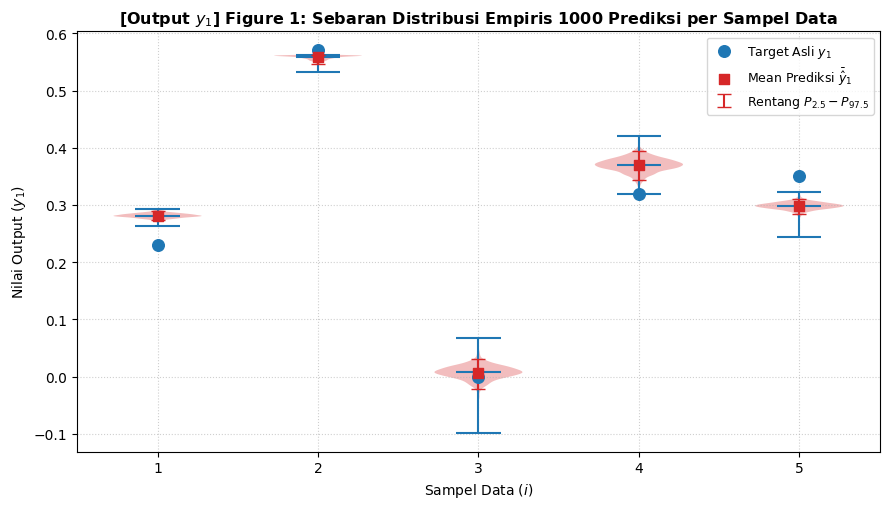

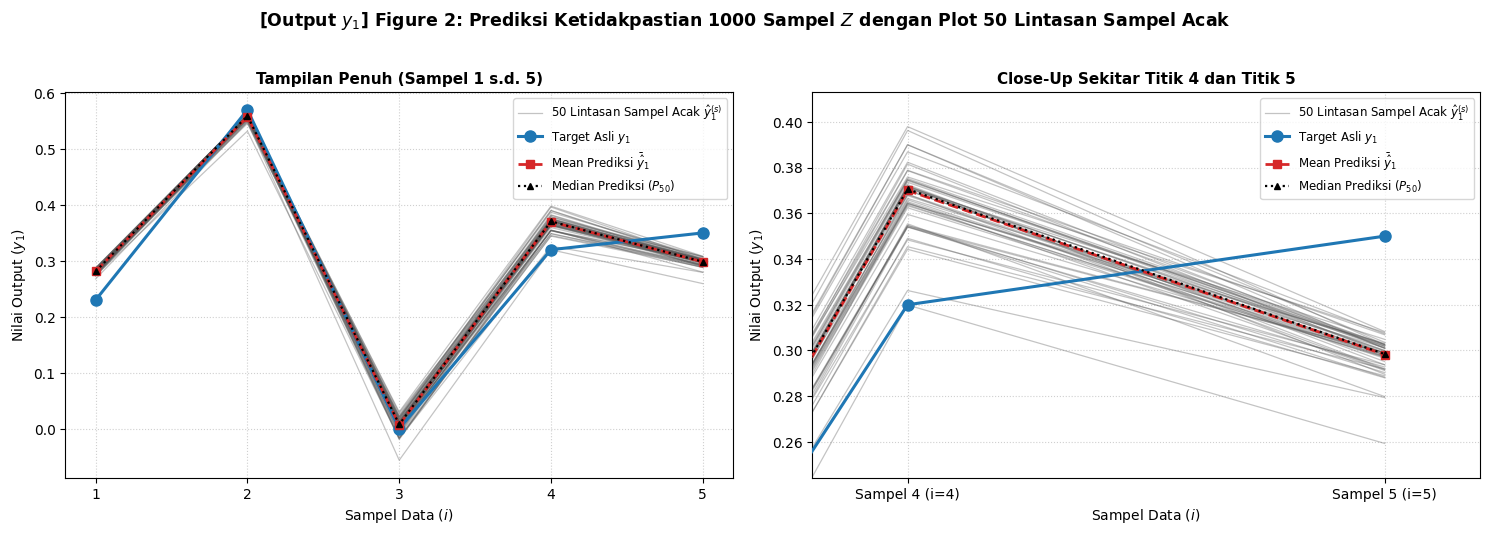

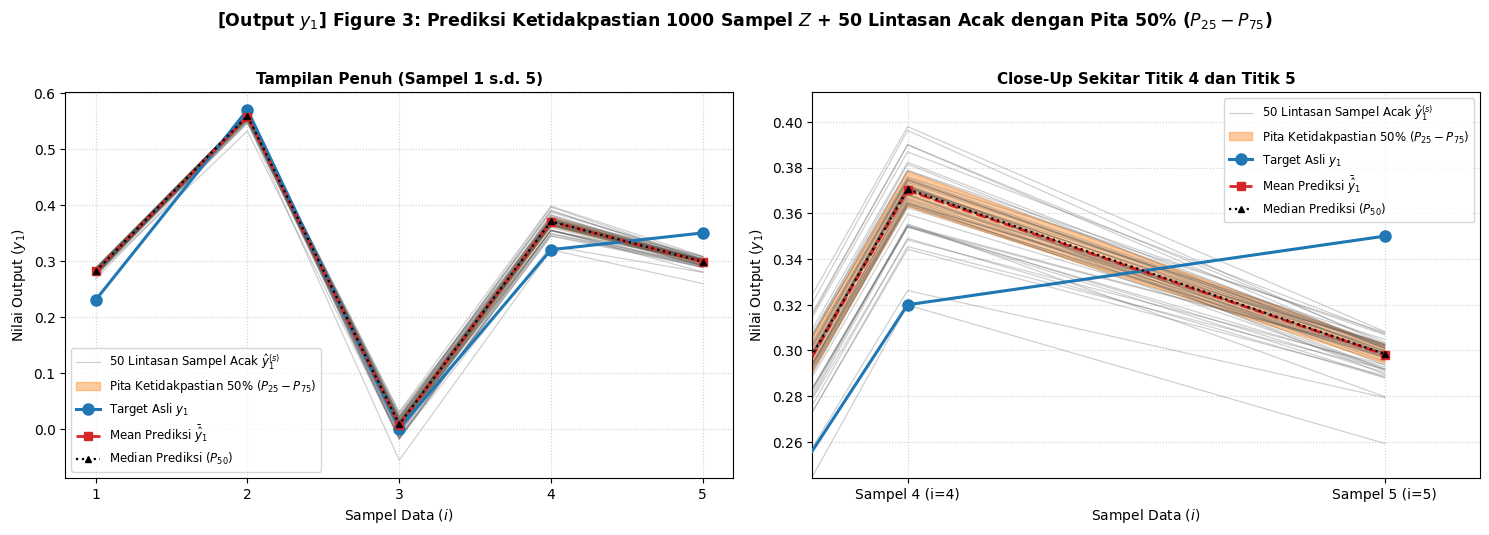

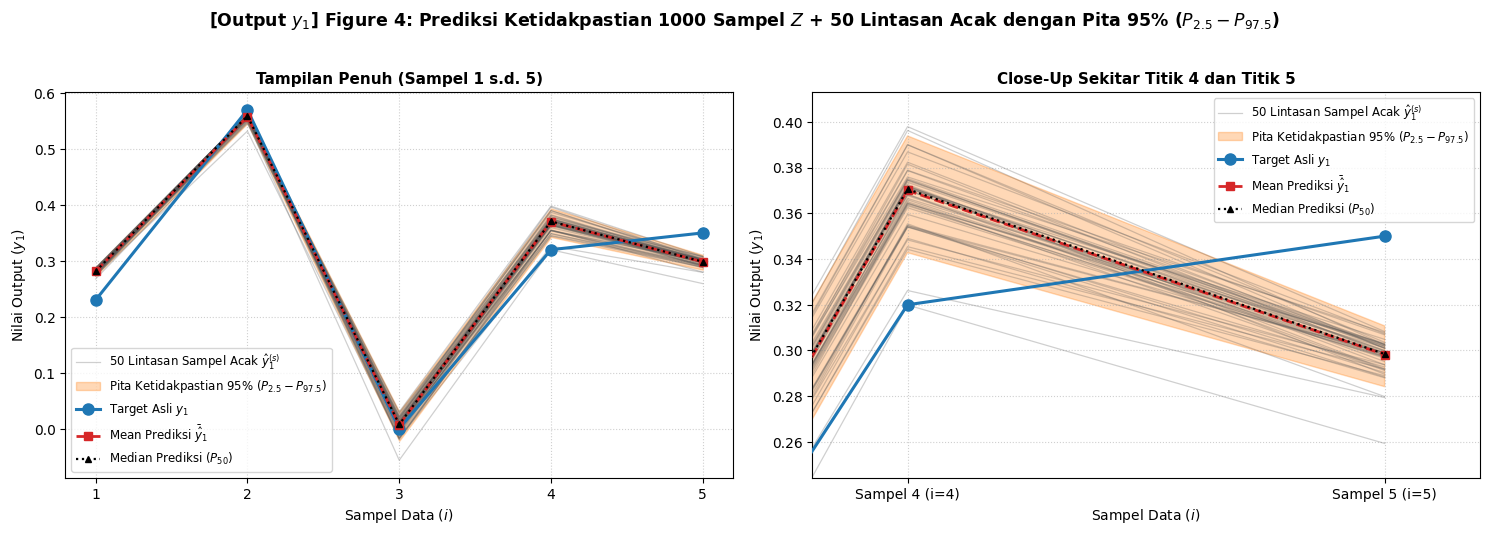

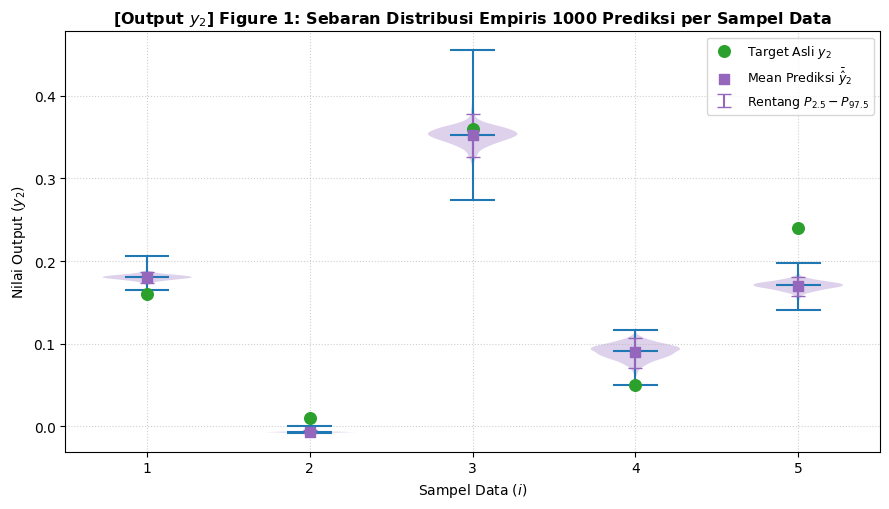

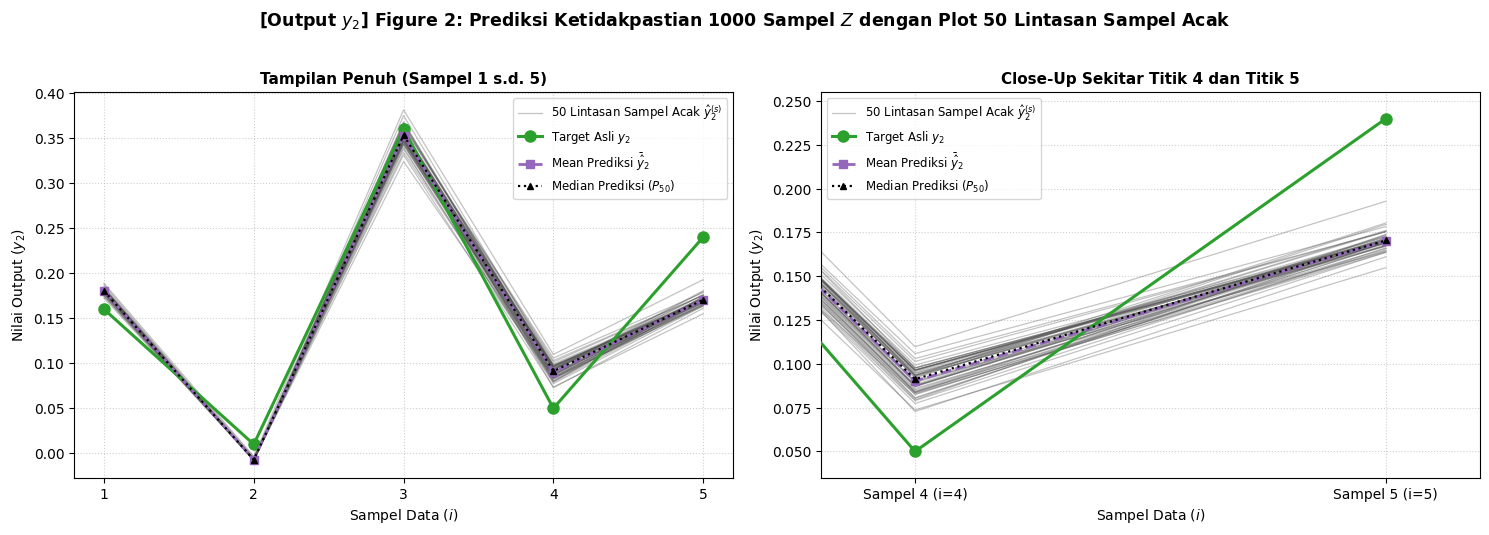

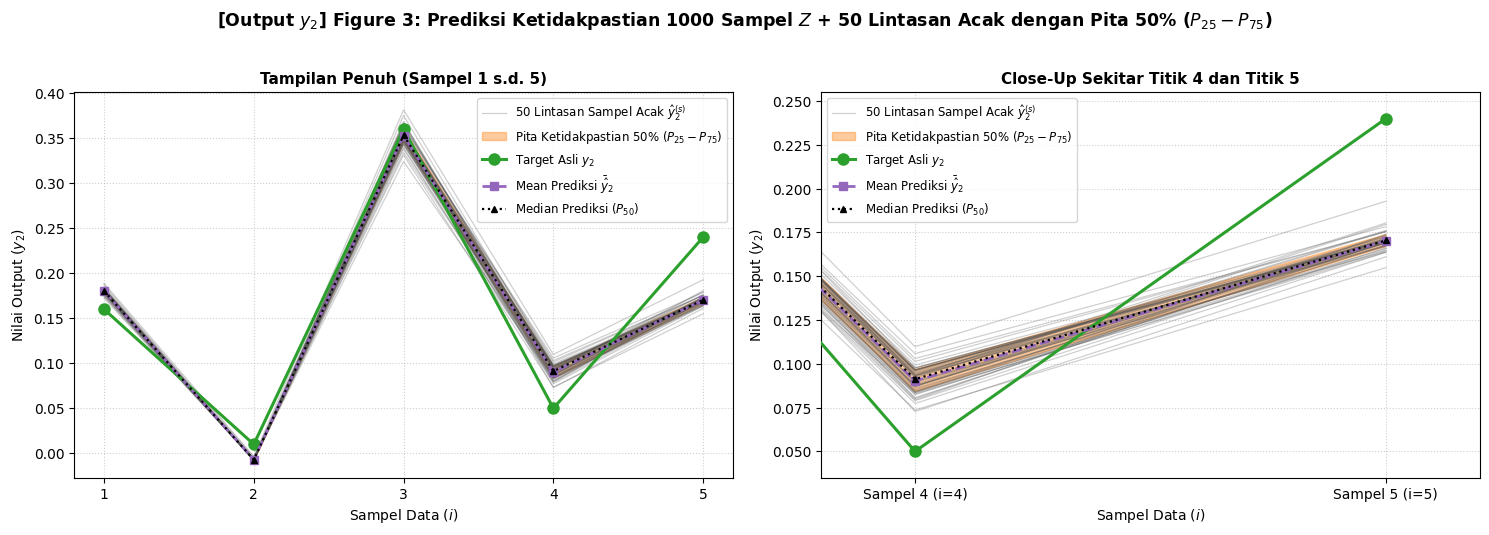

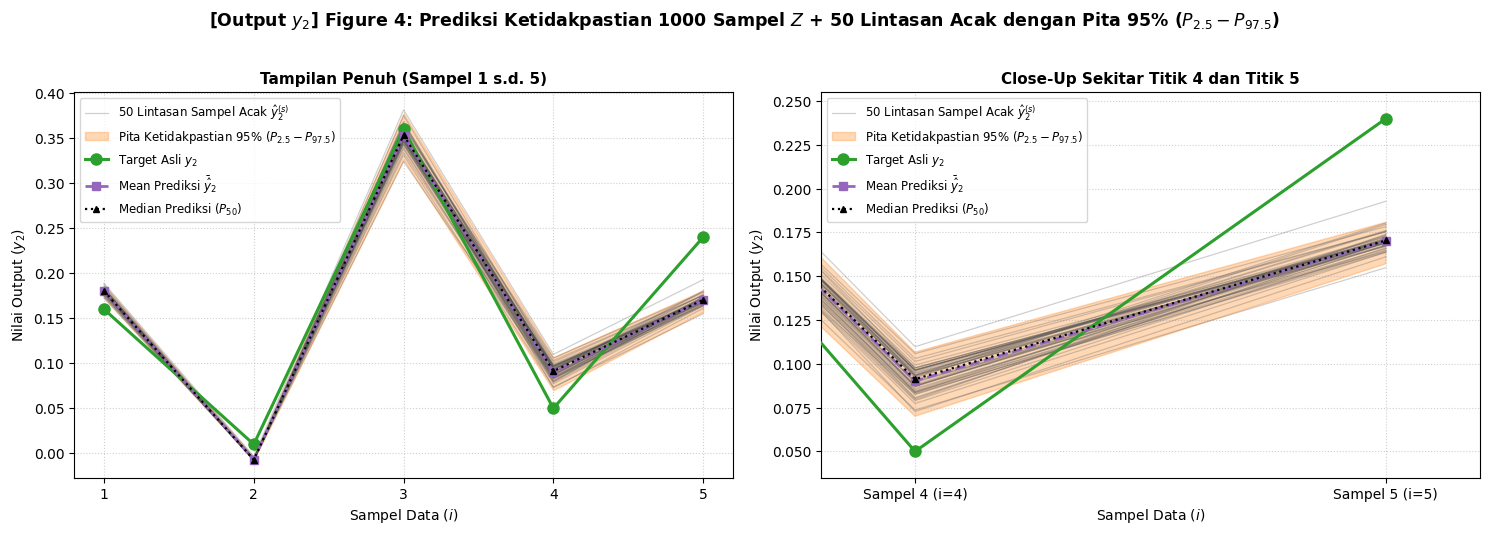

In [5]:
# =========================================================================
# TAHAP 4: VISUALISASI 4 FIGURE PITA KETIDAKPASTIAN (UNCERTAINTY BAND) R^3 -> R^2
# =========================================================================
samples = np.arange(1, N + 1)
colors = ['#d62728', '#9467bd']
target_colors = ['#1f77b4', '#2ca02c']

for out_idx in range(2):
    c_pred = colors[out_idx]
    c_targ = target_colors[out_idx]
    
    y_zoom_min = min(np.min(Y_hat_mc[:50, 3:5, out_idx]), np.min(perc_values[0, 3:5, out_idx]), np.min(Y[3:5, out_idx])) - 0.015
    y_zoom_max = max(np.max(Y_hat_mc[:50, 3:5, out_idx]), np.max(perc_values[6, 3:5, out_idx]), np.max(Y[3:5, out_idx])) + 0.015
    
    # =========================================================================
    # FIGURE 1: Sebaran Distribusi Empiris 1000 Prediksi per Sampel Data (1 Plot)
    # =========================================================================
    fig1, ax1 = plt.subplots(figsize=(9, 5.2))
    parts = ax1.violinplot([Y_hat_mc[:, i, out_idx] for i in range(N)], positions=samples,
                           showmeans=False, showmedians=True, widths=0.55)
    for pc in parts['bodies']:
        pc.set_facecolor(c_pred)
        pc.set_alpha(0.30)
        
    ax1.scatter(samples, Y[:, out_idx], color=c_targ, s=70, zorder=5, label=rf'Target Asli $y_{out_idx+1}$')
    ax1.scatter(samples, mean_pred[:, out_idx], color=c_pred, marker='s', s=55, zorder=5, label=rf'Mean Prediksi $\bar{{\hat{{y}}}}_{out_idx+1}$')
    ax1.errorbar(samples, mean_pred[:, out_idx],
                 yerr=[mean_pred[:, out_idx] - perc_values[0, :, out_idx], perc_values[6, :, out_idx] - mean_pred[:, out_idx]],
                 fmt='none', ecolor=c_pred, elinewidth=1.5, capsize=5, label=r'Rentang $P_{2.5} - P_{97.5}$')
    
    ax1.set_title(f'[Output $y_{out_idx+1}$] Figure 1: Sebaran Distribusi Empiris 1000 Prediksi per Sampel Data', fontsize=11.5, fontweight='bold')
    ax1.set_xlabel('Sampel Data ($i$)', fontsize=10)
    ax1.set_ylabel(f'Nilai Output ($y_{out_idx+1}$)', fontsize=10)
    ax1.set_xticks(samples)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(fontsize=9, loc='best')
    plt.tight_layout()
    plt.show()
    
    # Fungsi pembantu untuk membuat Figure 2, 3, dan 4 (Kiri: Full, Kanan: Close-Up Titik 4 & 5)
    def plot_full_and_closeup_r2(fig_num, title_suffix, band_type=None):
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
        for idx, is_zoom in enumerate([False, True]):
            ax = axes[idx]
            for s in range(50):
                ax.plot(samples, Y_hat_mc[s, :, out_idx], color='#555555', alpha=0.35 if not band_type else 0.28,
                        linewidth=0.9, label=rf'50 Lintasan Sampel Acak $\hat{{y}}_{out_idx+1}^{{(s)}}$' if s == 0 else "")
                
            if band_type == '50':
                ax.fill_between(samples, perc_values[2, :, out_idx], perc_values[4, :, out_idx],
                                color='#ff7f0e', alpha=0.40, label=r'Pita Ketidakpastian 50% ($P_{25} - P_{75}$)')
            elif band_type == '95':
                ax.fill_between(samples, perc_values[0, :, out_idx], perc_values[6, :, out_idx],
                                color='#ff7f0e', alpha=0.30, label=r'Pita Ketidakpastian 95% ($P_{2.5} - P_{97.5}$)')
                
            ax.plot(samples, Y[:, out_idx], 'o-', color=c_targ, linewidth=2.2, markersize=8, zorder=5, label=rf'Target Asli $y_{out_idx+1}$')
            ax.plot(samples, mean_pred[:, out_idx], 's--', color=c_pred, linewidth=2.0, markersize=6, zorder=5, label=rf'Mean Prediksi $\bar{{\hat{{y}}}}_{out_idx+1}$')
            ax.plot(samples, perc_values[3, :, out_idx], '^:', color='black', linewidth=1.6, markersize=5, zorder=5, label=r'Median Prediksi ($P_{50}$)')
            
            if not is_zoom:
                ax.set_xticks(samples)
                ax.set_title('Tampilan Penuh (Sampel 1 s.d. 5)', fontsize=11, fontweight='bold')
            else:
                ax.set_xlim(3.8, 5.2)
                ax.set_ylim(y_zoom_min, y_zoom_max)
                ax.set_xticks([4, 5])
                ax.set_xticklabels(['Sampel 4 (i=4)', 'Sampel 5 (i=5)'])
                ax.set_title('Close-Up Sekitar Titik 4 dan Titik 5', fontsize=11, fontweight='bold')
                
            ax.set_xlabel('Sampel Data ($i$)', fontsize=10)
            ax.set_ylabel(f'Nilai Output ($y_{out_idx+1}$)', fontsize=10)
            ax.grid(True, linestyle=':', alpha=0.6)
            ax.legend(fontsize=8.5, loc='best')
            
        fig.suptitle(f'[Output $y_{out_idx+1}$] Figure {fig_num}: {title_suffix}', fontsize=12.5, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()

    # FIGURE 2, 3, 4 untuk masing-masing komponen output
    plot_full_and_closeup_r2(2, 'Prediksi Ketidakpastian 1000 Sampel $Z$ dengan Plot 50 Lintasan Sampel Acak', band_type=None)
    plot_full_and_closeup_r2(3, 'Prediksi Ketidakpastian 1000 Sampel $Z$ + 50 Lintasan Acak dengan Pita 50% ($P_{25} - P_{75}$)', band_type='50')
    plot_full_and_closeup_r2(4, 'Prediksi Ketidakpastian 1000 Sampel $Z$ + 50 Lintasan Acak dengan Pita 95% ($P_{2.5} - P_{97.5}$)', band_type='95')
